In [148]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from IPython.display import display

# **Cargar archivos**

In [149]:
train = pd.read_csv("/content/train.csv")
test = pd.read_csv("/content/test.csv")
gender_submission = pd.read_csv("/content/gender_submission.csv")
print("TRAIN")
print("Dimensiones:", train.shape)
display(train.head())

print("\nTEST")
print("Dimensiones:", test.shape)
display(test.head())

print("\nGENDER SUBMISSION")
print("Dimensiones:", gender_submission.shape)
display(gender_submission.head())

TRAIN
Dimensiones: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



TEST
Dimensiones: (418, 11)


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



GENDER SUBMISSION
Dimensiones: (418, 2)


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


# Resumen de tipos, nulos y cardinalidad


In [150]:
resumen = pd.DataFrame({
    'Tipo': train.dtypes.astype(str),
    'No nulos': train.notna().sum(),
    'Nulos': train.isna().sum(),
    '% Nulos': (train.isna().mean()*100).round(2),
    'Únicos': train.nunique(dropna=True)
})
display(resumen)

print('Filas duplicadas en train:', train.duplicated().sum())
print('Filas duplicadas en test :', test.duplicated().sum())

,Tipo,No nulos,Nulos,% Nulos,Únicos
PassengerId,int64,891,0,0.00,891
Survived,int64,891,0,0.00,2
Pclass,int64,891,0,0.00,3
Name,object,891,0,0.00,891
Sex,object,891,0,0.00,2
Age,float64,714,177,19.87,88
SibSp,int64,891,0,0.00,7
Parch,int64,891,0,0.00,7
Ticket,object,891,0,0.00,681
Fare,float64,891,0,0.00,248


Filas duplicadas en train: 0
Filas duplicadas en test : 0


# Estadística descriptiva

In [151]:
print('Resumen numérico de train.csv')
display(train.describe().T.round(2))

Resumen numérico de train.csv


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


# Missing values de train y test


In [152]:
missing_train = pd.DataFrame({
    'Missing': train.isna().sum(),
    'Porcentaje': (train.isna().mean()*100).round(2)
}).query('Missing > 0')

missing_test = pd.DataFrame({
    'Missing': test.isna().sum(),
    'Porcentaje': (test.isna().mean()*100).round(2)
}).query('Missing > 0')

print('Missing values - train.csv')
display(missing_train)
print('\nMissing values - test.csv')
display(missing_test)

Missing values - train.csv


,Missing,Porcentaje
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22



Missing values - test.csv


,Missing,Porcentaje
Age,86,20.57
Fare,1,0.24
Cabin,327,78.23


# Gráfico de datos faltantes

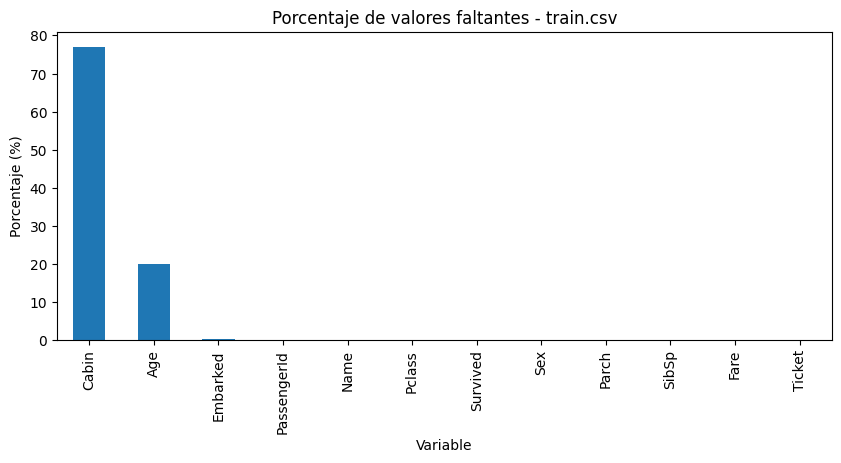

In [153]:
(train.isna().mean()*100).sort_values(ascending=False).plot(kind='bar', figsize=(10,4))
plt.title('Porcentaje de valores faltantes - train.csv')
plt.ylabel('Porcentaje (%)')
plt.xlabel('Variable')
plt.show()


# Distribución de la variable objetivo y patrones relevantes

In [154]:
conteo = train['Survived'].value_counts().sort_index()
porcentaje = (train['Survived'].value_counts(normalize=True).sort_index()*100).round(2)
print('Conteo Survived:')
print(conteo)
print('\nPorcentaje Survived:')
print(porcentaje)

print('\nSupervivencia por sexo (%)')
print((train.groupby('Sex')['Survived'].mean()*100).round(2))

print('\nSupervivencia por clase (%)')
print((train.groupby('Pclass')['Survived'].mean()*100).round(2))

Conteo Survived:
Survived
0    549
1    342
Name: count, dtype: int64

Porcentaje Survived:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64

Supervivencia por sexo (%)
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Supervivencia por clase (%)
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64


# Gráficos descriptivos

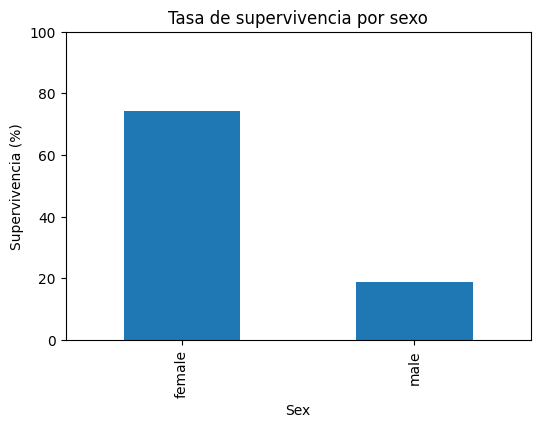

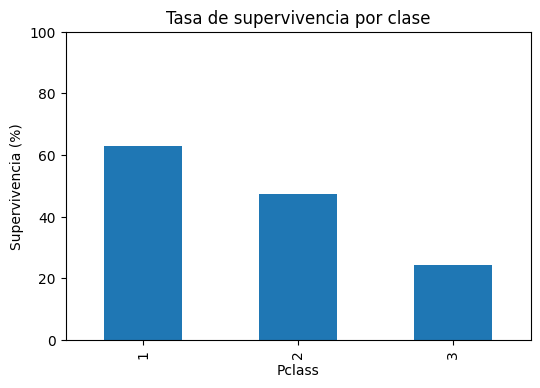

,Q1,Q3,IQR,Límite inferior,Límite superior,Cantidad atípicos,% atípicos
Age,20.12,38.0,17.88,-6.69,64.81,11.0,1.54
Fare,7.91,31.0,23.09,-26.72,65.63,116.0,13.02


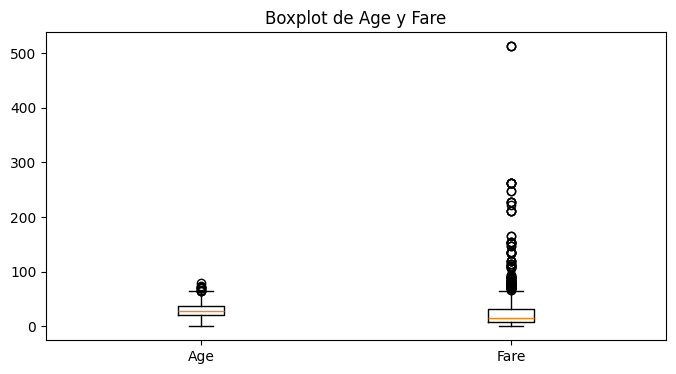

In [155]:
(train.groupby('Sex')['Survived'].mean()*100).plot(kind='bar', figsize=(6,4))
plt.title('Tasa de supervivencia por sexo')
plt.ylabel('Supervivencia (%)')
plt.ylim(0,100)
plt.show()

(train.groupby('Pclass')['Survived'].mean()*100).plot(kind='bar', figsize=(6,4))
plt.title('Tasa de supervivencia por clase')
plt.ylabel('Supervivencia (%)')
plt.xlabel('Pclass')
plt.ylim(0,100)
plt.show()

def resumen_iqr(df, columna):
    s = df[columna].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    li = q1 - 1.5 * iqr
    ls = q3 + 1.5 * iqr
    outliers = s[(s < li) | (s > ls)]
    return pd.Series({
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Límite inferior': li,
        'Límite superior': ls,
        'Cantidad atípicos': len(outliers),
        '% atípicos': round(len(outliers)/len(s)*100, 2)
    })

outliers_resumen = pd.DataFrame({
    'Age': resumen_iqr(train, 'Age'),
    'Fare': resumen_iqr(train, 'Fare')
}).T

display(outliers_resumen.round(2))

plt.figure(figsize=(8,4))
plt.boxplot([train['Age'].dropna(), train['Fare'].dropna()], tick_labels=['Age','Fare'])
plt.title('Boxplot de Age y Fare')
plt.show()

train_clean = train.copy()
test_clean = test.copy()

# Duplicados

In [156]:
train_clean = train_clean.drop_duplicates().reset_index(drop=True)
test_clean = test_clean.drop_duplicates().reset_index(drop=True)


# Parámetros calculados desde train

In [157]:
mediana_age = train['Age'].median()
moda_embarked = train['Embarked'].mode()[0]
mediana_fare = train['Fare'].median()

# Missing values

In [158]:
for df in [train_clean, test_clean]:
    df['Age'] = df['Age'].fillna(mediana_age)
    df['Embarked'] = df['Embarked'].fillna(moda_embarked)
    df['Fare'] = df['Fare'].fillna(mediana_fare)

# Cabin: conservar sólo la información de presencia/ausencia

In [159]:
for df in [train_clean, test_clean]:
    df['HasCabin'] = df['Cabin'].notna().astype(int)
    df.drop(columns=['Cabin'], inplace=True)

# Capping de Fare

In [160]:
q1_fare = train['Fare'].quantile(0.25)
q3_fare = train['Fare'].quantile(0.75)
iqr_fare = q3_fare - q1_fare
limite_sup_fare = q3_fare + 1.5 * iqr_fare

train_clean['Fare'] = train_clean['Fare'].clip(upper=limite_sup_fare)
test_clean['Fare'] = test_clean['Fare'].clip(upper=limite_sup_fare)

print('Mediana Age:', mediana_age)
print('Moda Embarked:', moda_embarked)
print('Mediana Fare:', mediana_fare)
print('Límite superior Fare:', round(limite_sup_fare, 4))

Mediana Age: 28.0
Moda Embarked: S
Mediana Fare: 14.4542
Límite superior Fare: 65.6344


# Verificación de limpieza

In [161]:
print('Nulos restantes en train_clean:')
print(train_clean.isna().sum()[train_clean.isna().sum() > 0])
print('\nNulos restantes en test_clean:')
print(test_clean.isna().sum()[test_clean.isna().sum() > 0])

print('\nDimensiones finales:')
print('train_clean:', train_clean.shape)
print('test_clean :', test_clean.shape)
display(train_clean.head())


Nulos restantes en train_clean:
Series([], dtype: int64)

Nulos restantes en test_clean:
Series([], dtype: int64)

Dimensiones finales:
train_clean: (891, 12)
test_clean : (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,65.6344,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,0


# Variables para un modelo base
# PassengerId, Name y Ticket se excluyen por identificación/alta cardinalidad.

In [162]:
features = ['Pclass','Sex','Age','SibSp','Parch','Fare','Embarked','HasCabin']
X = train_clean[features].copy()
y = train_clean['Survived'].copy()

# 70% train - 30% temporal

In [163]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 15% validation - 15% test interno

In [164]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

resumen_split = pd.DataFrame({
    'Muestra': ['Train','Validation','Test interno'],
    'Registros': [len(X_train), len(X_val), len(X_test)],
    '% del total': [len(X_train)/len(X)*100, len(X_val)/len(X)*100, len(X_test)/len(X)*100],
    '% Survived=1': [y_train.mean()*100, y_val.mean()*100, y_test.mean()*100]
}).round(2)

display(resumen_split)


,Muestra,Registros,% del total,% Survived=1
0,Train,623,69.92,38.36
1,Validation,134,15.04,38.81
2,Test interno,134,15.04,38.06


# Codificación simple para dejar las muestras listas para modelado

In [165]:
X_train_model = pd.get_dummies(X_train, columns=['Sex','Embarked'], drop_first=True, dtype=int)
X_val_model = pd.get_dummies(X_val, columns=['Sex','Embarked'], drop_first=True, dtype=int)
X_test_model = pd.get_dummies(X_test, columns=['Sex','Embarked'], drop_first=True, dtype=int)

# Alinear las columnas

In [166]:
X_val_model = X_val_model.reindex(columns=X_train_model.columns, fill_value=0)
X_test_model = X_test_model.reindex(columns=X_train_model.columns, fill_value=0)

print('Dimensiones para modelado:')
print('X_train:', X_train_model.shape)
print('X_val  :', X_val_model.shape)
print('X_test :', X_test_model.shape)

Dimensiones para modelado:
X_train: (623, 9)
X_val  : (134, 9)
X_test : (134, 9)


# En Colab se guardan en /content

In [167]:
# Carpeta de salida en Google Colab
salida = "/content"

# Guardar bases limpias
train_clean.to_csv(f"{salida}/train_clean.csv", index=False)
test_clean.to_csv(f"{salida}/test_clean.csv", index=False)

# Crear archivos de entrenamiento, validación y test
train_split = X_train.copy()
train_split["Survived"] = y_train

val_split = X_val.copy()
val_split["Survived"] = y_val

test_split = X_test.copy()
test_split["Survived"] = y_test

# Guardar archivos
train_split.to_csv(f"{salida}/train_split.csv", index=False)
val_split.to_csv(f"{salida}/validation_split.csv", index=False)
test_split.to_csv(f"{salida}/test_interno_split.csv", index=False)

print("Archivos guardados correctamente en:", salida)

Archivos guardados correctamente en: /content
